# Piloto Focal Loss — resumen de los tres Transformers

Reúne los resultados de `Piloto_FocalLoss_RoBERTuito`, `Piloto_FocalLoss_BETO` y `Piloto_FocalLoss_DistilBETO` (solo train oficial, 3 folds agrupados, época del refit). No entrena nada. Si falta algún modelo, lo indica y continúa con los disponibles.

**Regla de decisión (la misma en los tres pilotos):** una opción de Focal Loss se adopta en un modelo solo si su IC 95 % frente a la entropía cruzada actual (`CE`) queda por encima de 0 en al menos 2 de las 3 variantes.

In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PILOTOS_DIR = Path("../../data/pilotos_focal_loss")
MODELOS = ["BETO", "DistilBETO", "RoBERTuito"]
VARIANTES = ["mx", "es", "cu"]
OPCIONES = ["CE", "FL_g1", "FL_g2", "FL_g2_LS"]

resumenes, comparaciones = [], []
for modelo in MODELOS:
    carpeta = PILOTOS_DIR / modelo.lower()
    r = carpeta / f"{modelo.lower()}_piloto_focal_resumen.csv"
    c = carpeta / f"{modelo.lower()}_piloto_focal_comparacion.csv"
    if not (r.exists() and c.exists()):
        print(f"{modelo}: piloto aún no ejecutado (faltan los CSV en {carpeta}).")
        continue
    resumenes.append(pd.read_csv(r).assign(modelo=modelo))
    comparaciones.append(pd.read_csv(c).assign(modelo=modelo))

if not resumenes:
    raise SystemExit("No hay resultados de ningún piloto todavía.")
RES = pd.concat(resumenes, ignore_index=True)
COMP = pd.concat(comparaciones, ignore_index=True)

tabla = (RES.pivot_table(index=["modelo", "opcion"], columns="variante", values="f1_oof")
         .reindex(columns=VARIANTES))
tabla["general"] = tabla.mean(axis=1)
tabla = tabla.reindex([(m, o) for m in MODELOS for o in OPCIONES if (m, o) in tabla.index])
print("F1-Macro OOF (época del refit) por modelo y función de error:")
display(tabla.round(4))

COMP["dif_ic95"] = COMP.apply(lambda f: f"{f.dif_vs_CE:+.4f} [{f.ic95_inf:+.4f}, {f.ic95_sup:+.4f}]", axis=1)
print("Diferencia con CE [IC 95 % bootstrap pareado]:")
display(COMP.pivot_table(index=["modelo", "opcion"], columns="variante", values="dif_ic95", aggfunc="first")
        .reindex(columns=VARIANTES))

decision = (COMP.groupby(["modelo", "opcion"])["mejora_clara"].sum().astype(int).rename("variantes_con_mejora")
            .reset_index())
decision["se_adopta"] = decision["variantes_con_mejora"] >= 2
display(decision)

PILOTOS_DIR.mkdir(parents=True, exist_ok=True)
tabla.round(4).to_csv(PILOTOS_DIR / "piloto_focal_f1_oof.csv")
COMP.to_csv(PILOTOS_DIR / "piloto_focal_comparacion_todos.csv", index=False)
decision.to_csv(PILOTOS_DIR / "piloto_focal_decision.csv", index=False)

DistilBETO: piloto aún no ejecutado (faltan los CSV en ..\..\data\pilotos_focal_loss\distilbeto).
RoBERTuito: piloto aún no ejecutado (faltan los CSV en ..\..\data\pilotos_focal_loss\robertuito).
F1-Macro OOF (época del refit) por modelo y función de error:


variante             mx      es      cu  general
modelo opcion                                   
BETO   CE        0.6609  0.7333  0.7206   0.7049
       FL_g1     0.6557  0.7315  0.7170   0.7014
       FL_g2     0.6553  0.7334  0.7143   0.7010
       FL_g2_LS  0.6509  0.7320  0.7172   0.7001

Diferencia con CE [IC 95 % bootstrap pareado]:


variante                                 mx                          es  \
modelo opcion                                                             
BETO   FL_g1     -0.0052 [-0.0131, +0.0023]  -0.0018 [-0.0088, +0.0052]   
       FL_g2     -0.0056 [-0.0136, +0.0032]  +0.0001 [-0.0082, +0.0083]   
       FL_g2_LS  -0.0099 [-0.0185, -0.0017]  -0.0013 [-0.0086, +0.0063]   

variante                                 cu  
modelo opcion                                
BETO   FL_g1     -0.0035 [-0.0120, +0.0044]  
       FL_g2     -0.0063 [-0.0167, +0.0034]  
       FL_g2_LS  -0.0033 [-0.0125, +0.0055]

,modelo,opcion,variantes_con_mejora,se_adopta
0,BETO,FL_g1,0,False
1,BETO,FL_g2,0,False
2,BETO,FL_g2_LS,0,False


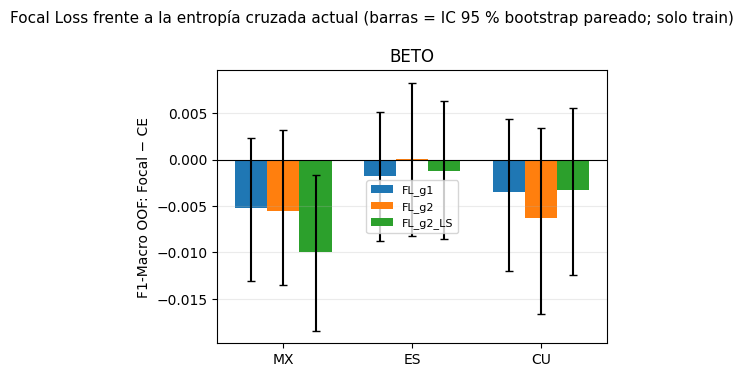

In [3]:
modelos = [m for m in MODELOS if m in set(COMP["modelo"])]
opciones_fl = [o for o in OPCIONES if o != "CE"]
fig, axes = plt.subplots(1, len(modelos), figsize=(5.0 * len(modelos), 3.8), sharey=True, squeeze=False)
ancho = 0.25
for ax, modelo in zip(axes[0], modelos):
    d = COMP[COMP["modelo"] == modelo]
    for j, opcion in enumerate(opciones_fl):
        x = np.arange(len(VARIANTES)) + (j - 1) * ancho
        f = d[d["opcion"] == opcion].set_index("variante").reindex(VARIANTES)
        ax.bar(x, f["dif_vs_CE"], width=ancho, label=opcion,
               yerr=[f["dif_vs_CE"] - f["ic95_inf"], f["ic95_sup"] - f["dif_vs_CE"]], capsize=3)
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_xticks(range(len(VARIANTES)), [v.upper() for v in VARIANTES])
    ax.set_title(modelo)
    ax.grid(axis="y", alpha=0.25)
axes[0, 0].set_ylabel("F1-Macro OOF: Focal − CE")
axes[0, 0].legend(fontsize=8)
fig.suptitle("Focal Loss frente a la entropía cruzada actual (barras = IC 95 % bootstrap pareado; solo train)",
             fontsize=11)
fig.tight_layout()
for ext in ("png", "pdf"):
    fig.savefig(PILOTOS_DIR / f"piloto_focal_diferencias.{ext}", dpi=200, bbox_inches="tight")
plt.show()

## Cómo reportarlo en el artículo

- **Si ninguna opción se adopta:** "En un piloto con el train oficial (3 folds agrupados, configuración final de cada modelo) se reemplazó la entropía cruzada binaria ponderada por Focal Loss (Lin et al., 2017) con γ ∈ {1, 2}, con y sin *label smoothing*. Ninguna variante mejoró de forma consistente el F1-Macro *out-of-fold* (IC 95 % bootstrap pareado), por lo que se mantuvo la entropía cruzada ponderada." Se añade la tabla de diferencias como material complementario.
- **Si alguna se adopta:** se fija esa función de error y se repite el entrenamiento final y la evaluación en el test del notebook 04 del modelo correspondiente (5 semillas), declarando que la función de error se eligió con este piloto sobre el train.